# 🫀 Actividad en frío – Exploración de Señales ECG

> **Procesamiento Digital de Voz e Imágenes en la era de la Inteligencia Artificial**  
> Dora María Ballesteros  
> Primera edición, 2026  
> ISBN: 978-1-957395-68-5

> 🔗 **[Consultar el libro en Editorial REDIPE](https://editorial.redipe.org/index.php/1/catalog/book/260)**

---



## 🫀 Estructura de los archivos del MIT-BIH Arrhythmia Database

En esta actividad trabajaremos con el MIT-BIH Arrhythmia Database, específicamente con los registros ECG **100 y 119**, comparando los latidos anotados como **A** y **V** con los latidos normales (**N**) en el **dominio del tiempo**, **tiempo-frecuencia** y **frecuencia**.

Cada registro ECG está asociado a diferentes archivos que contienen la señal, sus características y las anotaciones realizadas por expertos.

### 📈 `.dat` — Data
Contiene las muestras de la señal ECG en formato binario. Incluye los valores digitales registrados en los diferentes canales.

### 📋 `.hea` — Header
Archivo de cabecera que describe las características de la señal:
- ⏱️ Frecuencia de muestreo.
- 📊 Número de canales.
- 🔢 Cantidad de muestras.
- ⚙️ Ganancia y unidades de medida.

### 🏷️ `.atr` — Annotation
Contiene las anotaciones de referencia realizadas por expertos:
- 📍 Ubicación temporal de los latidos cardíacos.
- ❤️ Clasificación de los latidos.
- 🔎 Identificación de otros eventos relevantes.

Estas anotaciones constituyen el **ground truth** para tareas de clasificación de arritmias.

### 🖥️ `.xws` — Waveform Viewer Settings
Archivo de configuración asociado a la visualización de las señales mediante herramientas de PhysioNet/WFDB.

Puede almacenar parámetros de visualización, pero no contiene las muestras ECG ni las anotaciones de referencia.

---

### 💡 ¿Qué archivos necesitamos?

| Archivo | Función | Uso |
|:---:|---|:---:|
| 📈 `.dat` | Muestras de la señal ECG | ✅ Necesario |
| 📋 `.hea` | Información y configuración de la señal | ✅ Necesario |
| 🏷️ `.atr` | Anotaciones y etiquetas de referencia | ✅ Para clasificación supervisada |
| 🖥️ `.xws` | Configuración de visualización | ⭕ Opcional |

> 🎯 **Importante:** Para cargar y procesar las señales ECG utilizaremos los archivos `.dat` y `.hea`. Para identificar y clasificar los diferentes tipos de latidos cardíacos, utilizaremos las anotaciones contenidas en los archivos `.atr`.


### 📌 Instrucciones

1. **Descarga** este Notebook y ejecútalo en Google Colab.
2. **Carga** el archivo `mit_dataset.zip` sin descomprimirlo.
3. **Ejecuta** las celdas en el orden presentado.
4. **Observa, compara y analiza** los resultados de ambos registros.
5. **Responde** las preguntas directamente en el Notebook.

> Esta actividad se realiza antes de la explicación del tema. El objetivo es explorar las señales, identificar patrones y formular tus propias conclusiones para su posterior discusión en clase.

## 🫀 Componentes principales de una señal ECG


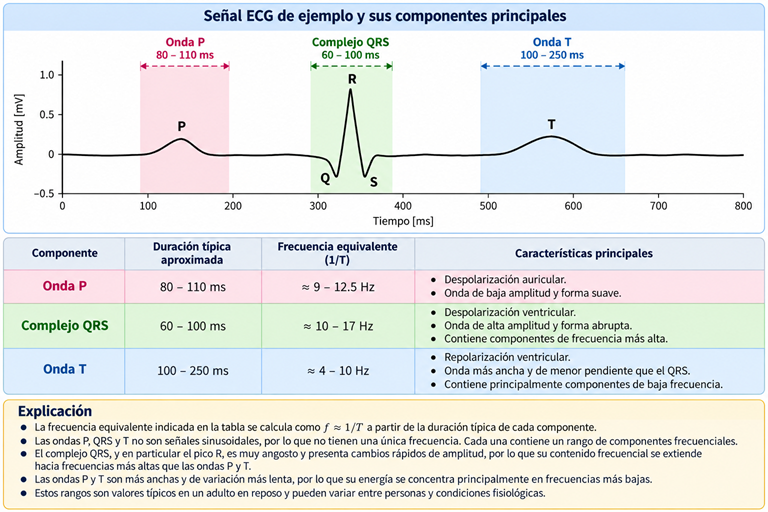

# **I.  IMPORTE E INSTALACIÓN DE LIBRERÍAS**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


### 📌 Librería WFDB

**WFDB (WaveForm DataBase)** permite leer los registros fisiológicos del MIT-BIH:

- `rdrecord()`: carga la **señal ECG**.
- `rdann()`: carga las **anotaciones de los latidos** (`N`, `A`, `V`, etc.).

In [ ]:
!pip install wfdb

# **II. DESCOMPRIMIR ARCHIVO ZIP**

In [ ]:
from pathlib import Path
import zipfile

# ==========================================
# 1. Rutas del dataset
# ==========================================

ZIP_PATH = Path("mit_dataset.zip")
DATA_DIR = Path("mit_dataset")

# ==========================================
# 2. Descomprimir solo si es necesario
# ==========================================

if not DATA_DIR.exists():
    print("Descomprimiendo dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

    print("Dataset descomprimido correctamente.")

else:
    print("El dataset ya se encuentra descomprimido.")

print(f"Ruta de trabajo: {DATA_DIR.resolve()}")

# **III.  CARGAR REGISTRO**

In [ ]:
import wfdb

def cargar_registro(numero, data_dir=DATA_DIR):

    archivo_hea = next(data_dir.rglob(f"{numero}.hea"))
    ruta_base = archivo_hea.with_suffix("")

    record = wfdb.rdrecord(str(ruta_base))
    annotation = wfdb.rdann(str(ruta_base), "atr")

    return record, annotation

# **IV.  SEÑAL EN EL DOMINIO DEL TIEMPO**

In [ ]:
registros = ["100", "119"]

duracion = 10

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, registro in zip(axes, registros):

    record, annotation = cargar_registro(registro)
    fs = record.fs
    ecg = record.p_signal[:, 0]

    N = int(duracion * fs)
    t = np.arange(N) / fs

    # Anotaciones
    mask = annotation.sample < N
    ann_samples = annotation.sample[mask]
    ann_symbols = np.array(annotation.symbol)[mask]
    ann_time = ann_samples / fs

    # Gráfica
    ax.plot(t, ecg[:N])
    ax.scatter(ann_time, ecg[ann_samples])

    for tiempo, muestra, simbolo in zip(ann_time, ann_samples, ann_symbols):
        ax.text(tiempo, ecg[muestra] + 0.1, simbolo, ha="center")

    ax.set_xticks(np.arange(0, duracion + 0.5, 0.5))
    ax.set_ylabel("Amplitud [mV]")
    ax.set_title(f"ECG con anotaciones - Registro {registro}")
    ax.grid()

axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

### **Análisis en el dominio del tiempo**

1. **Localiza** los latidos anotados como **A** y **V** y compáralos con los latidos normales (**N**) cercanos.
2. **Identifica** las principales diferencias de los patrones A y V respecto a los latidos normales, considerando su **morfología, amplitud, duración e intervalo R-R**.
3. **Compara** los patrones A y V. ¿Qué características temporales permiten diferenciarlos?

# **V.  ESPECTROGRAMA DE LA SEÑAL**

In [ ]:
from scipy.signal import spectrogram

registros = ["100", "119"]
duracion = 10
f_max = 25

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

for ax, registro in zip(axes, registros):

    record, _ = cargar_registro(registro)
    fs = record.fs
    ecg = record.p_signal[:, 0]
    N = int(duracion * fs)

    # Espectrograma
    f, t_spec, Sxx = spectrogram(ecg[:N], fs=fs, nperseg=128, noverlap=96)
    Sxx_dB = 10 * np.log10(Sxx + 1e-12)

    mask_f = f <= f_max
    datos = Sxx_dB[mask_f, :]
    vmin, vmax = np.percentile(datos, [10, 90])

    im = ax.pcolormesh(t_spec, f[mask_f], datos, shading="auto",
                       cmap="inferno", vmin=vmin, vmax=vmax)

    ax.set_xticks(np.arange(0, duracion + 1, 1))
    ax.set_ylabel("Frecuencia [Hz]")
    ax.set_title(f"Espectrograma del ECG - Registro {registro} - Canal MLII")

    fig.colorbar(im, ax=ax, label="Potencia [dB]")

axes[-1].set_xlabel("Tiempo [s]")
plt.tight_layout()
plt.show()

### **Análisis tiempo-frecuencia**

1. **Localiza** en los espectrogramas los latidos anotados como **A** y **V**.
2. **Compara** su representación tiempo-frecuencia con la de los latidos normales, considerando la **distribución de energía, contenido frecuencial y duración**.
3. **Identifica** qué características del espectrograma permiten diferenciar los patrones **A, V y N**.

# **VI.  ESPECTRO DE LA SEÑAL**

In [ ]:
registros = ["100", "119"]
duracion = 10
f_max = 25

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, registro in zip(axes, registros):

    record, _ = cargar_registro(registro)
    fs = record.fs
    ecg = record.p_signal[:, 0]
    N = int(duracion * fs)

    # FFT
    x = ecg[:N] - np.mean(ecg[:N])
    X = np.fft.rfft(x)
    f_fft = np.fft.rfftfreq(len(x), d=1/fs)
    magnitud = np.abs(X) / len(x)

    # Frecuencias de interés
    mask_f = f_fft <= f_max

    ax.plot(f_fft[mask_f], magnitud[mask_f])
    ax.set_ylabel("Magnitud")
    ax.set_title(f"Espectro del ECG - Registro {registro} - Canal MLII")
    ax.grid()

axes[-1].set_xlabel("Frecuencia [Hz]")

plt.tight_layout()
plt.show()


### **Análisis en el dominio de la frecuencia**

1. **Compara** los espectros obtenidos para los dos registros e identifica sus principales diferencias.
2. **Analiza** si las diferencias observadas en los patrones **A y V** en el dominio del tiempo y en el espectrograma pueden identificarse directamente en los espectros.
3. **Explica** qué información se pierde al pasar de la representación tiempo-frecuencia al espectro.

## 📊 Rúbrica de evaluación – Experimento 1

RA **6.1**: Diseña y ejecuta protocolos experimentales para la evaluación de soluciones de Procesamiento Digital de Señales 1D o 2D, definiendo variables, métricas, procedimientos y criterios de análisis acordes con el problema estudiado.

- **Actividad en frío (exploratoria): 1/4 del Proyecto No. 1**

| Actividad | 0 | 3 | 5 |
|---|---|---|---|
| **Identifica los patrones N, A y V en el dominio del tiempo.** | No identifica los patrones. | Identifica parcialmente los patrones. | Identifica completamente los patrones. |
| **Identifica los patrones N, A y V en los espectrogramas.** | No identifica los patrones. | Identifica parcialmente los patrones. | Identifica completamente los patrones. |
| **Identifica diferencias entre los dos espectros.** | No identifica diferencias. | Identifica parcialmente las diferencias. | Identifica completamente las diferencias. |